# Visualisasi Pra-Pemrosesan Sekuensial Bertahap (Step-by-Step Preprocessing Pipeline)

Notebook ini menampilkan **tahapan pra-pemrosesan sinyal ECG Lead II secara sekuensial blok demi blok** dari dataset **Kachuee et al. (2016)**.

### Alur Eksekusi Blok demi Blok:
1. **Blok 0:** Setup, pemuatan data mentah, dan visualisasi awal sinyal ECG mentah beserta Ground Truth ABP.
2. **Blok 1 (Langkah 1):** Penerapan **IIR Notch Filter (50 Hz)** + Visualisasi Komparasi ECG Mentah vs Hasil Filter.
3. **Blok 2 (Langkah 2):** Penerapan **Butterworth Bandpass Filter (0.5 - 40 Hz)** + Visualisasi Komparasi ECG Mentah vs Hasil Filter.
4. **Blok 3 (Langkah 3):** Penerapan **Robust Scaling Normalization** + Visualisasi Komparasi ECG Mentah vs Hasil Normalisasi.
5. **Blok 4:** Rangkuman Ringkas 4 Panel Perbandingan Seluruh Tahapan.

## Blok 0: Setup, Pemuatan Data Mentah & Visualisasi Awal

Data berhasil dimuat: 1000 sampel @ 125.0 Hz (offset n_trim=50)
Ground Truth: SBP=126.4 | DBP=65.6 | MAP=88.3 mmHg


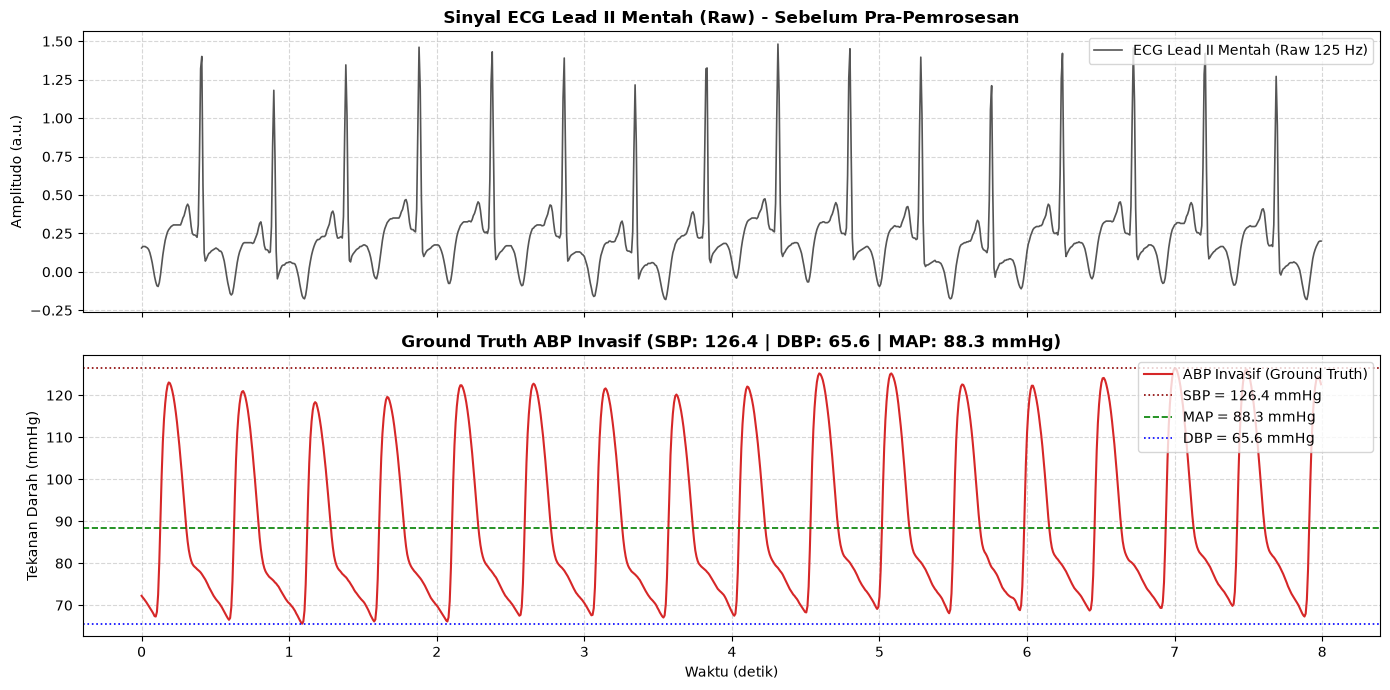

In [ ]:
import os
import sys
import socket
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import kagglehub

socket.setdefaulttimeout(300.0)

# Tambahkan path src ke sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from src.preprocessing.filters import iir_notch_filter, butterworth_bandpass_filter
from src.preprocessing.normalization import percentile_clip_scale

# -- Muat Dataset --
dataset_path = kagglehub.dataset_download("mkachuee/BloodPressureDataset")
mat_files = [os.path.join(r, f) for r, _, fs in os.walk(dataset_path) for f in sorted(fs) if f.endswith(".mat")]

first_mat = mat_files[0]
try:
    mat_data = scipy.io.loadmat(first_mat)
    cell_data = mat_data[[k for k in mat_data.keys() if not k.startswith("__")][0]]
except Exception:
    import h5py
    with h5py.File(first_mat, "r") as hf:
        cell_data = np.array(hf[list(hf.keys())[0]])

raw_rec = cell_data[0, 0] if cell_data.dtype == object else cell_data[0]
record_matrix = np.array(raw_rec, dtype=np.float64)
if record_matrix.shape[0] > record_matrix.shape[1] and record_matrix.shape[1] == 3:
    record_matrix = record_matrix.T

# -- Struktur sinyal Kachuee et al. (sesuai deskripsi dataset resmi) --
# row 0: PPG signal  @ 125 Hz  (photoplethysmograph from fingertip)
# row 1: ABP signal  @ 125 Hz  (invasive arterial blood pressure, mmHg)
# row 2: ECG signal  @ 125 Hz  (electrocardiogram channel II)

fs = 125.0
duration_sec = 8.0
n_samples = int(duration_sec * fs)
# n_trim: lewati sampel awal untuk menghindari filter edge artifact (transient tepi filtfilt).
n_trim = 50  # ~0.4 detik @ 125 Hz

ppg_raw = record_matrix[0, n_trim : n_trim + n_samples]  # PPG
abp_raw = record_matrix[1, n_trim : n_trim + n_samples]  # ABP (mmHg)
ecg_raw = record_matrix[2, n_trim : n_trim + n_samples]  # ECG Lead II
time_axis = np.arange(n_samples) / fs

# -- Hitung Ground Truth BP via deteksi puncak per beat (beat-by-beat) --
# Global max/min tidak digunakan karena dapat overestimate SBP / underestimate DBP akibat artefak.
# Metode: scipy.signal.find_peaks pada sinyal ABP invasif.
min_peak_dist = int(0.3 * fs)  # HR ≤ 200 bpm → jarak min ~37 sampel

systolic_peaks_idx, _ = find_peaks(
    abp_raw,
    distance=min_peak_dist,
    height=np.percentile(abp_raw, 50),
)
diastolic_troughs_idx, _ = find_peaks(-abp_raw, distance=min_peak_dist)

sbp_gt  = float(np.mean(abp_raw[systolic_peaks_idx]))   if len(systolic_peaks_idx)    > 0 else float(np.max(abp_raw))
dbp_gt  = float(np.mean(abp_raw[diastolic_troughs_idx])) if len(diastolic_troughs_idx) > 0 else float(np.min(abp_raw))
map_gt  = float(np.mean(abp_raw))
n_beats = len(systolic_peaks_idx)

print(f"Data berhasil dimuat: {n_samples} sampel @ {fs} Hz (offset n_trim={n_trim})")
print(f"Beat terdeteksi: {n_beats} beats")
print(f"Ground Truth: SBP={sbp_gt:.1f} | DBP={dbp_gt:.1f} | MAP={map_gt:.1f} mmHg")

# -- Visualisasi Awal: ECG Mentah + Ground Truth ABP --
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(time_axis, ecg_raw, color="#555555", linewidth=1.2, label="ECG Lead II Mentah (Raw 125 Hz)")
axes[0].set_title("Sinyal ECG Lead II Mentah (Raw) - Sebelum Pra-Pemrosesan", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Amplitudo (a.u.)")
axes[0].legend(loc="upper right")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(time_axis, abp_raw, color="#d62728", linewidth=1.5, label="ABP Invasif (Ground Truth)")
if len(systolic_peaks_idx) > 0:
    axes[1].scatter(time_axis[systolic_peaks_idx], abp_raw[systolic_peaks_idx],
                    color="darkred", s=45, zorder=5, label=f"Puncak Sistolik ({n_beats} beats)")
if len(diastolic_troughs_idx) > 0:
    axes[1].scatter(time_axis[diastolic_troughs_idx], abp_raw[diastolic_troughs_idx],
                    color="royalblue", s=45, marker="v", zorder=5, label="Lembah Diastolik")
axes[1].axhline(y=sbp_gt,  color="darkred",   linestyle=":",  linewidth=1.2, label=f"SBP (rata-rata per beat) = {sbp_gt:.1f} mmHg")
axes[1].axhline(y=map_gt,  color="green",      linestyle="--", linewidth=1.2, label=f"MAP = {map_gt:.1f} mmHg")
axes[1].axhline(y=dbp_gt,  color="royalblue",  linestyle=":",  linewidth=1.2, label=f"DBP (rata-rata per beat) = {dbp_gt:.1f} mmHg")
axes[1].set_title(
    f"Ground Truth ABP Invasif — Beat-by-Beat  (SBP: {sbp_gt:.1f} | DBP: {dbp_gt:.1f} | MAP: {map_gt:.1f} mmHg, n={n_beats})",
    fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Waktu (detik)")
axes[1].set_ylabel("Tekanan Darah (mmHg)")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


---

## Blok 1: Langkah 1 - IIR Notch Filter (Penghilang Noise 50 Hz PLN)

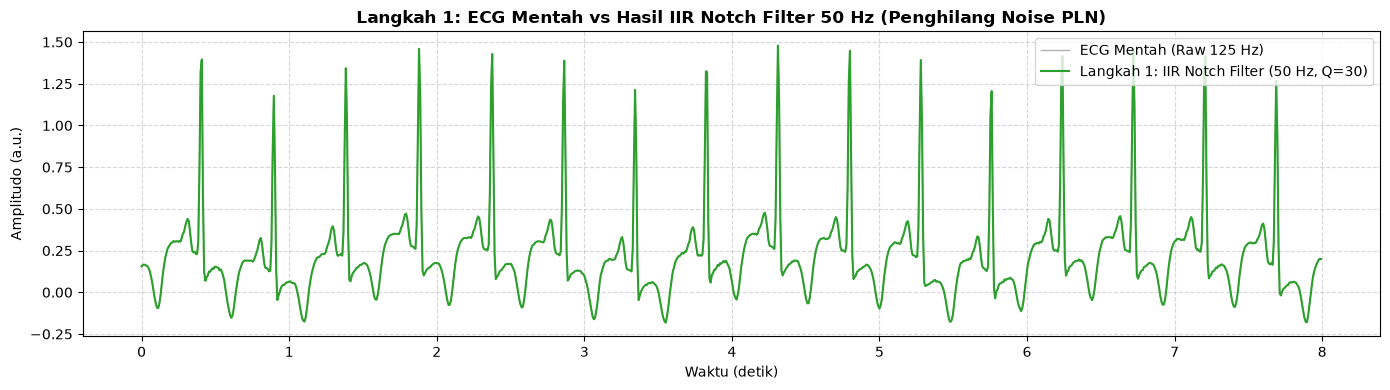

In [7]:
# Eksekusi Langkah 1: IIR Notch Filter 50 Hz (Q = 30, filtfilt)
ecg_step1_notch = iir_notch_filter(ecg_raw, fs=125.0, f0=50.0, q=30.0)

# Visualisasi Komparasi: ECG Mentah vs Setelah Notch Filter 50 Hz
fig, ax = plt.subplots(1, 1, figsize=(14, 4))

ax.plot(time_axis, ecg_raw, color="gray", alpha=0.6, linewidth=1.0, label="ECG Mentah (Raw 125 Hz)")
ax.plot(time_axis, ecg_step1_notch, color="#2ca02c", linewidth=1.5, label="Langkah 1: IIR Notch Filter (50 Hz, Q=30)")
ax.set_title("Langkah 1: ECG Mentah vs Hasil IIR Notch Filter 50 Hz (Penghilang Noise PLN)", fontsize=12, fontweight="bold")
ax.set_xlabel("Waktu (detik)")
ax.set_ylabel("Amplitudo (a.u.)")
ax.legend(loc="upper right")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---

## Blok 2: Langkah 2 - Butterworth Bandpass Filter (0.5 - 40 Hz)

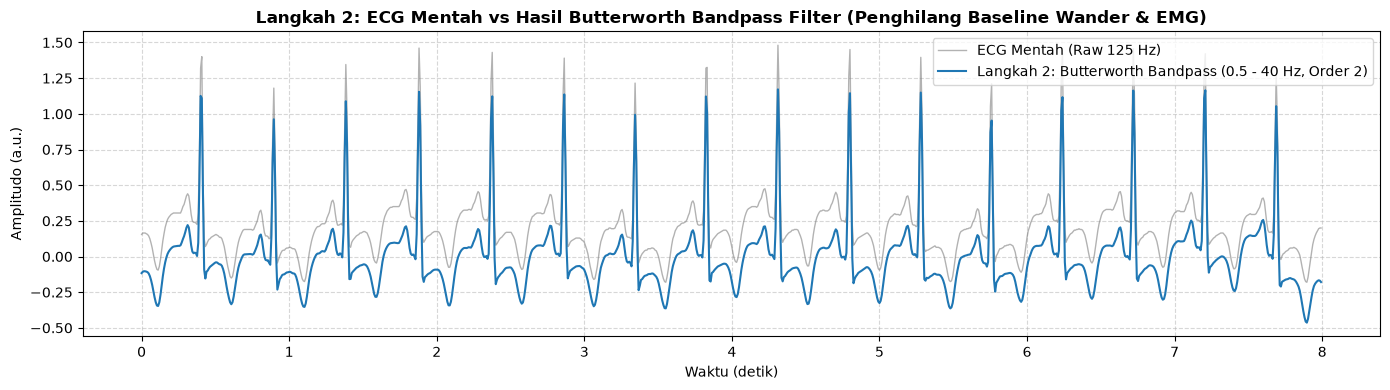

In [8]:
# Eksekusi Langkah 2: Butterworth Bandpass Filter (0.5 - 40 Hz, Order 2, filtfilt)
ecg_step2_bandpass = butterworth_bandpass_filter(ecg_step1_notch, fs=125.0, lowcut=0.5, highcut=40.0, order=2)

# Visualisasi Komparasi: ECG Mentah vs Setelah Bandpass Filter
fig, ax = plt.subplots(1, 1, figsize=(14, 4))

ax.plot(time_axis, ecg_raw, color="gray", alpha=0.6, linewidth=1.0, label="ECG Mentah (Raw 125 Hz)")
ax.plot(time_axis, ecg_step2_bandpass, color="#1f77b4", linewidth=1.5, label="Langkah 2: Butterworth Bandpass (0.5 - 40 Hz, Order 2)")
ax.set_title("Langkah 2: ECG Mentah vs Hasil Butterworth Bandpass Filter (Penghilang Baseline Wander & EMG)", fontsize=12, fontweight="bold")
ax.set_xlabel("Waktu (detik)")
ax.set_ylabel("Amplitudo (a.u.)")
ax.legend(loc="upper right")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---

## Blok 3: Langkah 3 - Normalisasi Amplitudo Robust Scaling

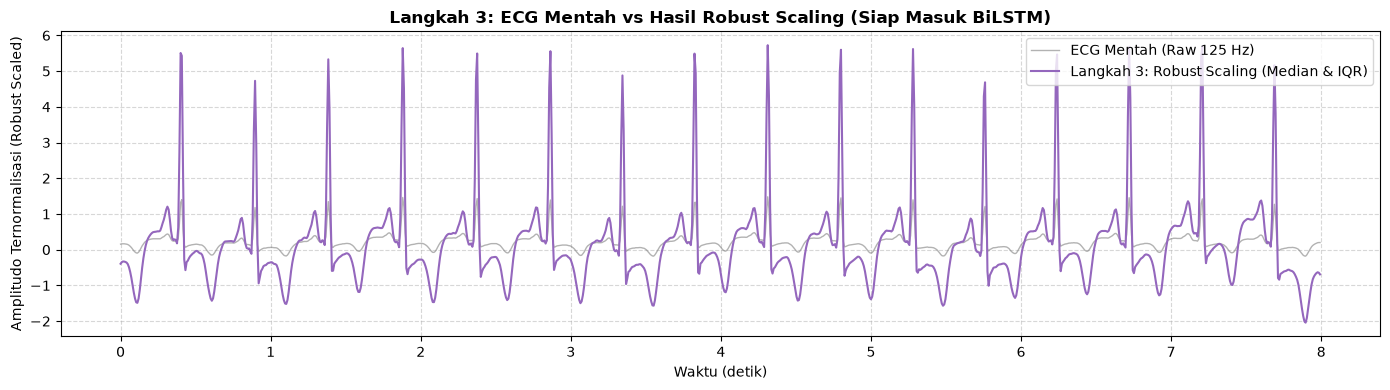

In [9]:
# Eksekusi Langkah 3: Normalisasi Amplitudo — Percentile Clipping & Scaling [0, 1]
# Formula (sesuai pipeline.py & Proposal Subbab 2.2.4):
#   x_clipped = clip(signal, Q1, Q99)
#   x_norm    = (x_clipped - Q1) / (Q99 - Q1 + eps)
#
# Catatan: fungsi ini konsisten dengan ECGPreprocessingPipeline.process()
# yang menggunakan percentile_clip_scale, bukan robust_scale.
ecg_step3_norm = percentile_clip_scale(ecg_step2_bandpass, q_low_percentile=1.0, q_high_percentile=99.0)

# Visualisasi Komparasi: ECG Mentah vs Hasil Normalisasi
fig, ax = plt.subplots(1, 1, figsize=(14, 4))

ax.plot(time_axis, ecg_raw, color="gray", alpha=0.6, linewidth=1.0, label="ECG Mentah (Raw 125 Hz)")
ax.plot(time_axis, ecg_step3_norm, color="#9467bd", linewidth=1.5,
        label="Langkah 3: Percentile Clip & Scale [0,1]  (Q1–Q99)")
ax.set_title("Langkah 3: ECG Mentah vs Hasil Normalisasi Percentile Clip & Scale [0, 1] (Siap Masuk BiLSTM)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Waktu (detik)")
ax.set_ylabel("Amplitudo Ternormalisasi [0–1]")
ax.legend(loc="upper right")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


---

## Blok 4: Rangkuman Perbandingan 4 Panel Seluruh Tahapan

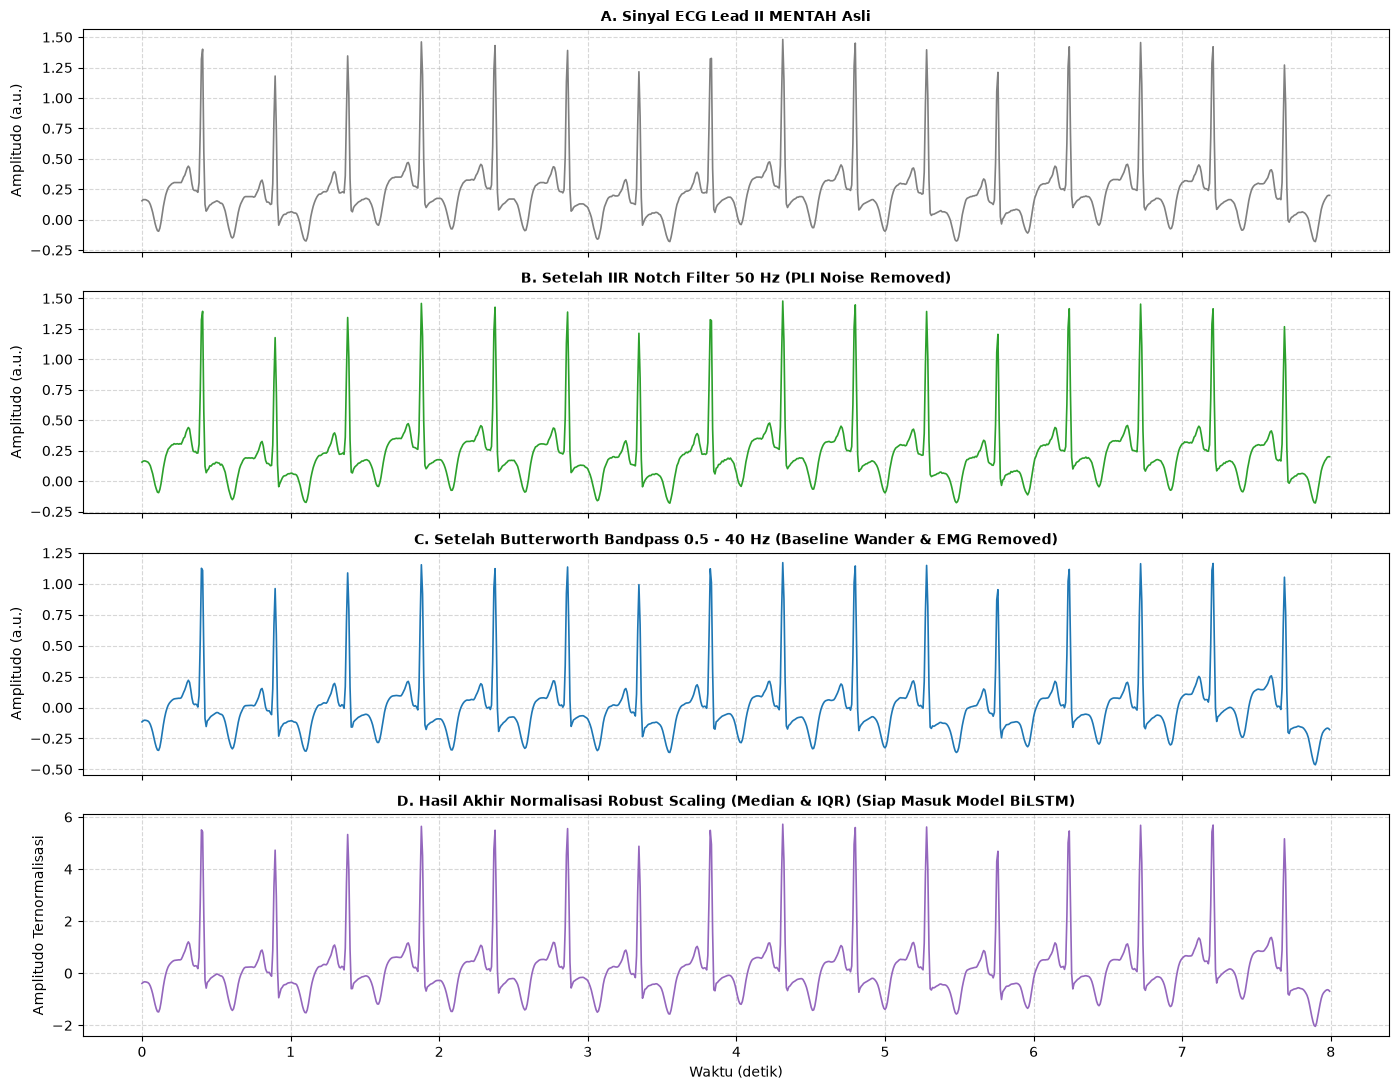

In [10]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

axes[0].plot(time_axis, ecg_raw, color="gray", linewidth=1.2)
axes[0].set_title("A. Sinyal ECG Lead II MENTAH Asli", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Amplitudo (a.u.)")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(time_axis, ecg_step1_notch, color="#2ca02c", linewidth=1.2)
axes[1].set_title("B. Setelah IIR Notch Filter 50 Hz (PLI Noise Removed)", fontsize=10, fontweight="bold")
axes[1].set_ylabel("Amplitudo (a.u.)")
axes[1].grid(True, linestyle="--", alpha=0.5)

axes[2].plot(time_axis, ecg_step2_bandpass, color="#1f77b4", linewidth=1.2)
axes[2].set_title("C. Setelah Butterworth Bandpass 0.5 - 40 Hz (Baseline Wander & EMG Removed)", fontsize=10, fontweight="bold")
axes[2].set_ylabel("Amplitudo (a.u.)")
axes[2].grid(True, linestyle="--", alpha=0.5)

axes[3].plot(time_axis, ecg_step3_norm, color="#9467bd", linewidth=1.2)
axes[3].set_title("D. Hasil Akhir Normalisasi Percentile Clip & Scale [0, 1] (Q1–Q99) (Siap Masuk Model BiLSTM)", fontsize=10, fontweight="bold")
axes[3].set_xlabel("Waktu (detik)")
axes[3].set_ylabel("Amplitudo Ternormalisasi [0–1]")
axes[3].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()